**Logistics Regression minor project**

Import the libraries

In [2]:
#Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [3]:
#Load the dataset
from google.colab import files
uploaded = files.upload()
csv_file=next(iter(uploaded))
df=pd.read_csv(csv_file)

Saving diabetes.csv to diabetes.csv


**Exploratory Data Analysis **


In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,y
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,y
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   y                         768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
#Check for missing values
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
y,0


In [8]:
#Check for duplicate values
df.duplicated().sum()

np.int64(0)

**Outlier identification and treatment**

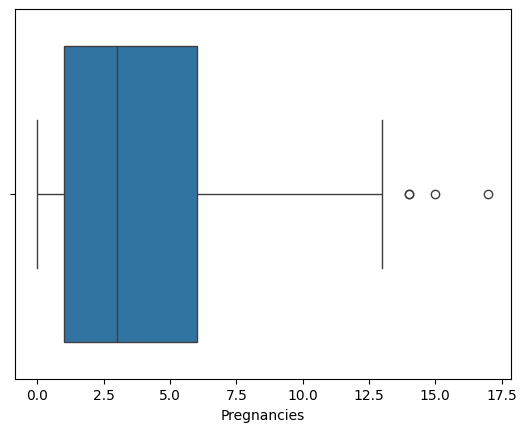

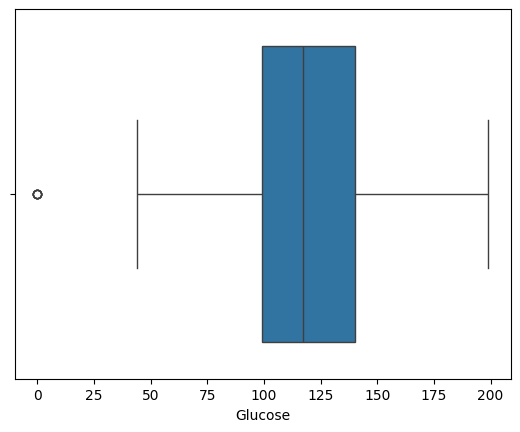

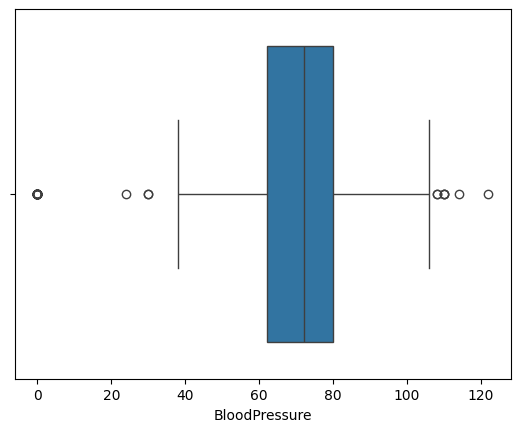

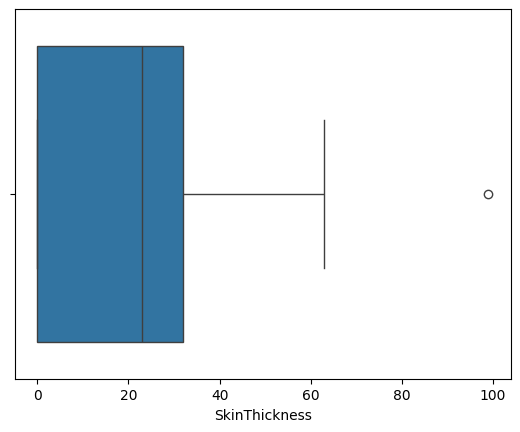

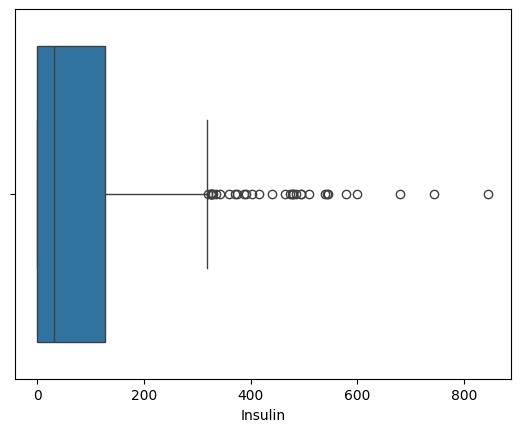

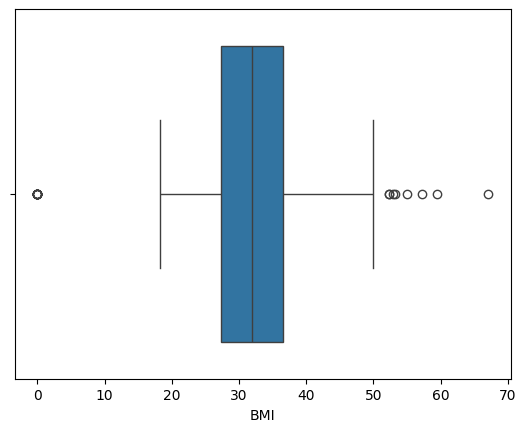

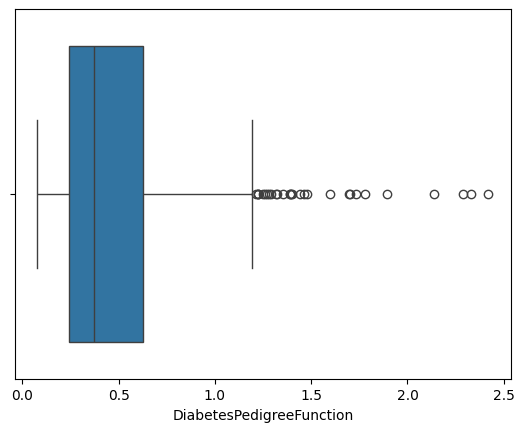

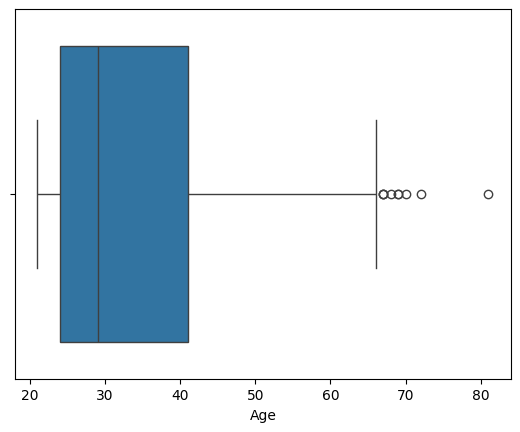

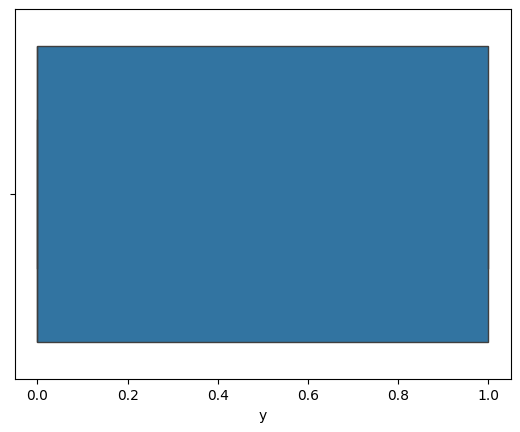

In [9]:
#Univariate analysis
columns = df.select_dtypes(include='number').columns
for column in columns:
  sns.boxplot(x=df[column])
  plt.show()

In [10]:
#Outlier treatment
columns=['Age','DiabetesPedigreeFunction','BMI','Insulin','SkinThickness','BloodPressure','Glucose','Pregnancies']
for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )


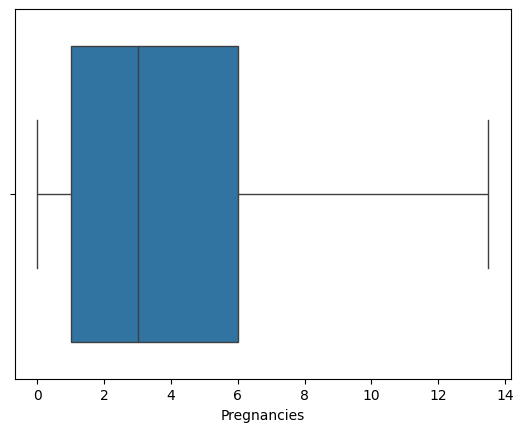

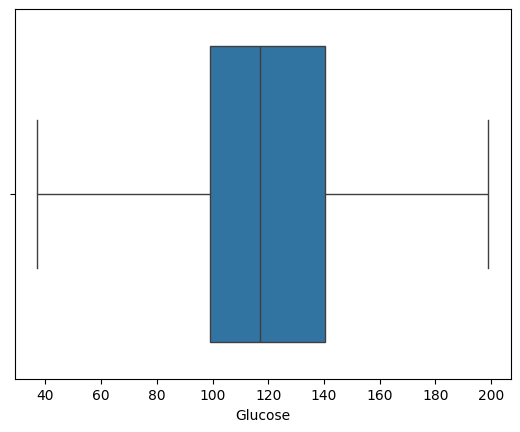

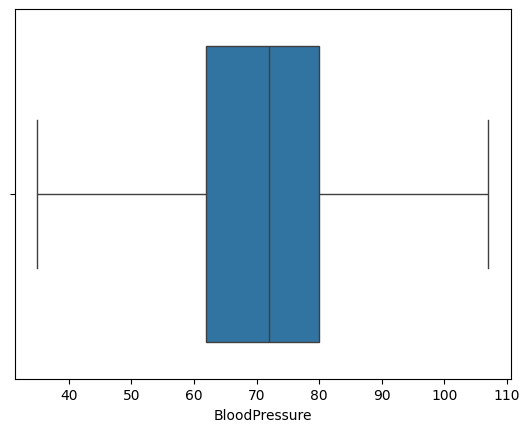

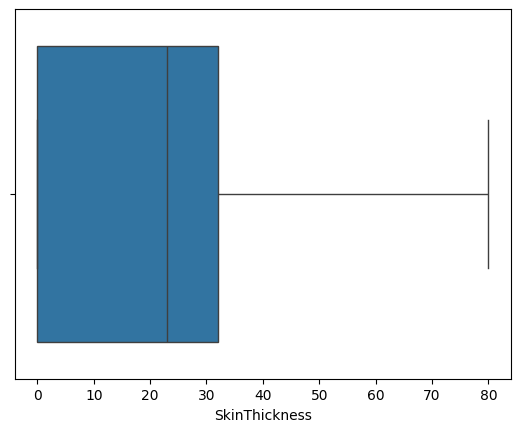

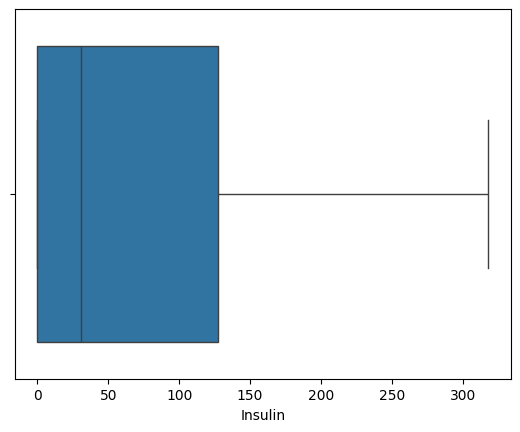

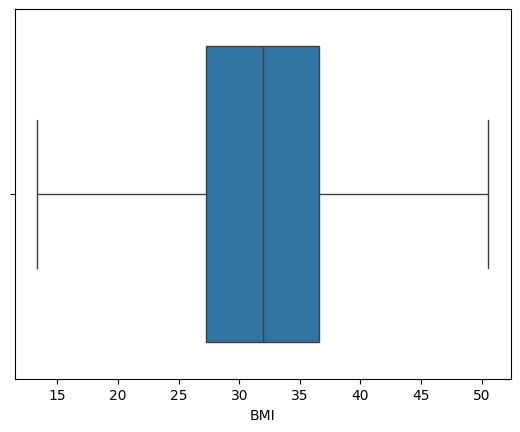

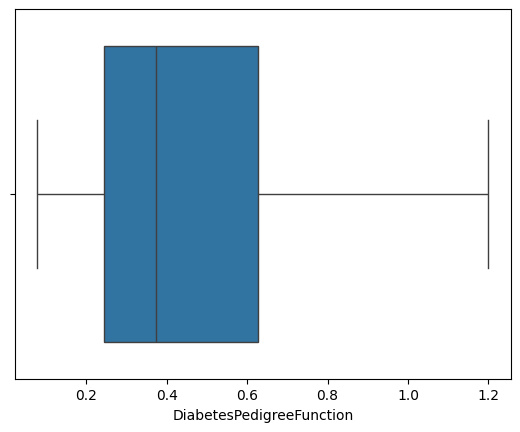

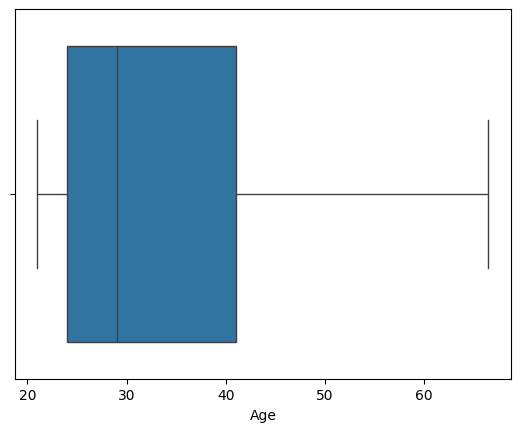

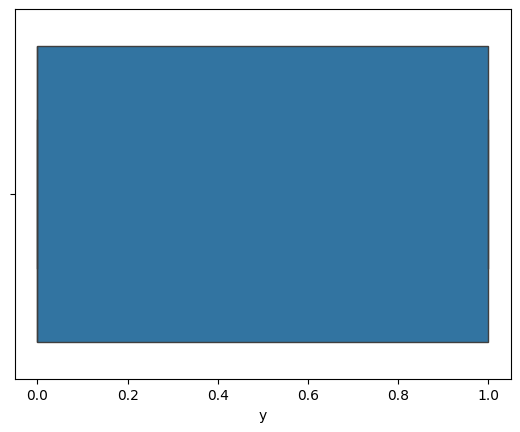

In [11]:
columns=df.select_dtypes(include='number').columns
for col in columns:
  sns.boxplot(x=df[col])
  plt.show()

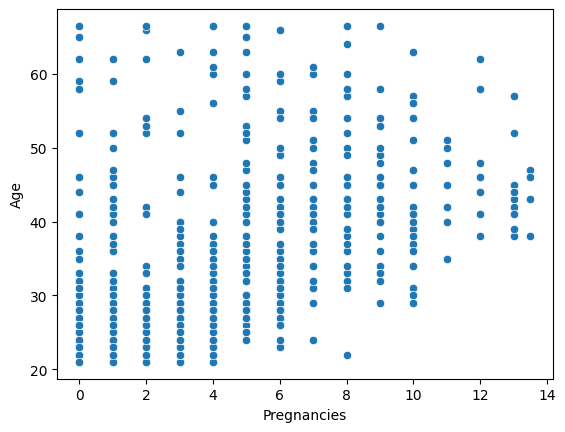

In [12]:
#Bivariate analysis
sns.scatterplot(x='Pregnancies',y='Age',data=df)
plt.show()

<Axes: xlabel='Insulin', ylabel='Count'>

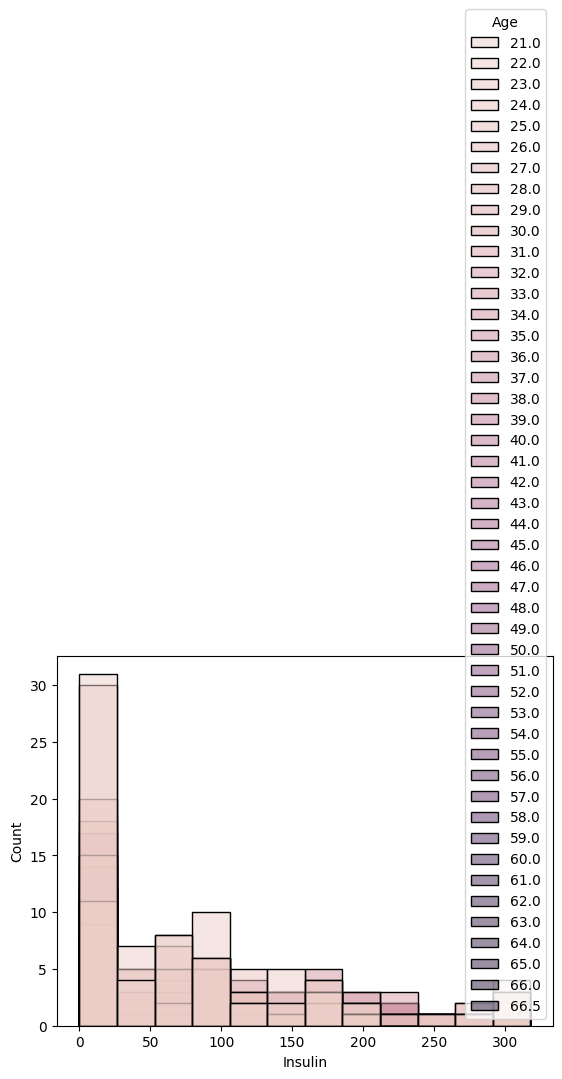

In [13]:
sns.histplot(x=df['Insulin'],hue=df['Age'],data=df)


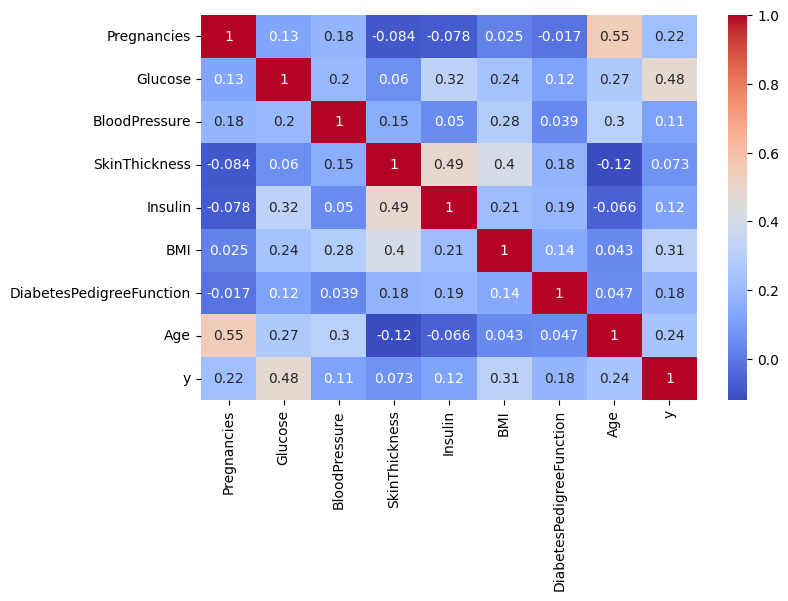

In [14]:
#Muiltivariate Analysis
plt.figure(figsize=(8,5))

sns.heatmap(df.corr(numeric_only = True), annot = True,cmap = 'coolwarm')

plt.show()

**Handling Invalid Zero Values**

In [15]:
columns_to_replace = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns_to_replace] = df[columns_to_replace].replace(0, np.nan)

print("Missing values after replacing invalid zeros:")
print(df.isnull().sum())

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       0
BloodPressure                 0
SkinThickness               227
Insulin                     374
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
y                             0
dtype: int64


**Feature Selection**

In [19]:
X = df.drop('y', axis=1)
y = df['y']

**Train-Test Split**

In [21]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**Handle Missing Values**

In [25]:

imputer = SimpleImputer(strategy='median')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

**Feature Scaling**

In [24]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Train Logistic Regression Model**

In [29]:

model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

**Make Predictions**

In [27]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

**Evaluate the Model**

In [28]:

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.7467532467532467
Precision: 0.6119402985074627
Recall   : 0.7592592592592593
F1-score : 0.6776859504132231
ROC-AUC  : 0.8198148148148148

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.74      0.79       100
           1       0.61      0.76      0.68        54

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.73       154
weighted avg       0.77      0.75      0.75       154



**Confusion Matrix**

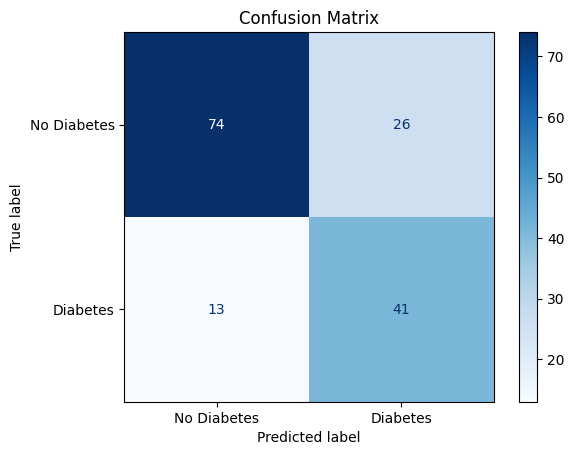

In [30]:


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['No Diabetes', 'Diabetes'],
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.show()

**ROC Curve**

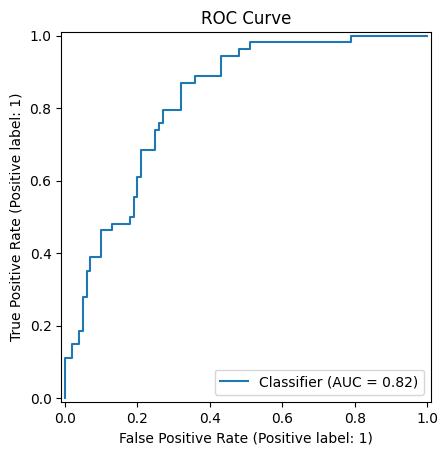

In [31]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title('ROC Curve')
plt.show()

**Actual vs Predicted Values**

In [32]:
results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print(results.head(10))

     Actual  Predicted
44        0          1
672       0          0
700       0          0
630       1          0
81        0          0
389       0          0
387       1          1
408       1          1
163       0          0
335       0          1
